# COMP813 — Error Analysis

## Cross-Dataset Classification Error Analysis

### Objective

This notebook analyses classification errors made by the three
models when evaluated on the unseen CEAS-08 dataset.

The analysis examines:

- False positives
- False negatives
- Error rates by model
- Agreement between models
- Email length
- Out-of-vocabulary rate
- Sequence truncation
- Representative misclassified examples

The purpose is to identify characteristics associated with model
errors and to distinguish model-specific errors from examples that
are difficult for multiple models.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import json

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

from collections import Counter

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
ceas_df = pd.read_csv(
    "ceas08_clean.csv"
)

print("CEAS-08 shape:", ceas_df.shape)
print(ceas_df.head())

CEAS-08 shape: (38964, 2)
                                                text  label
0  subject: never agree to be a loser body: buck ...      1
1  subject: befriend jenna jameson body: upgrade ...      1
2  subject: cnn.com daily top 10 body: >+=+=+=+=+...      1
3  subject: re: svn commit: r619753 - in /spamass...      0
4  subject: specialpricespharmmoreinfo body: welc...      1


In [3]:
X_ceas = ceas_df["text"].astype(str)
y_ceas = ceas_df["label"].to_numpy()

print("Emails:", len(X_ceas))
print("Labels:", len(y_ceas))

Emails: 38964
Labels: 38964


In [4]:
def tokenize_text(text):
    return re.findall(
        r"\b\w+\b",
        text.lower()
    )

print(
    tokenize_text(
        "This is a test email!"
    )
)

['this', 'is', 'a', 'test', 'email']


In [5]:
import joblib

lr_model = joblib.load(
    "../models/logistic_regression_enron.pkl"
)

svm_model = joblib.load(
    "../models/svm_enron.pkl"
)

lr_tfidf = joblib.load(
    "../models/tfidf_vectorizer.pkl"
)

svm_tfidf = joblib.load(
    "../models/tfidf_svm_vectorizer.pkl"
)

print("Classical models loaded successfully.")

Classical models loaded successfully.


In [6]:
X_ceas_lr = lr_tfidf.transform(X_ceas)

X_ceas_svm = svm_tfidf.transform(X_ceas)

lr_predictions = lr_model.predict(
    X_ceas_lr
)

svm_predictions = svm_model.predict(
    X_ceas_svm
)

print("Logistic Regression predictions:", len(lr_predictions))
print("SVM predictions:", len(svm_predictions))

Logistic Regression predictions: 38964
SVM predictions: 38964


In [7]:
with open(
    "../models/bilstm_vocabulary.json",
    "r"
) as f:

    bilstm_vocab = json.load(f)

bilstm_vocab_set = set(
    bilstm_vocab.keys()
)

print(
    "BiLSTM vocabulary size:",
    len(bilstm_vocab_set)
)

BiLSTM vocabulary size: 50000


In [8]:
import torch
import torch.nn as nn

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

class BiLSTMClassifier(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_layers,
        dropout
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_dim * 2,
            1
        )

    def forward(self, x):

        embedded = self.embedding(x)

        output, (hidden, cell) = self.lstm(
            embedded
        )

        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        hidden_combined = torch.cat(
            (
                forward_hidden,
                backward_hidden
            ),
            dim=1
        )

        hidden_combined = self.dropout(
            hidden_combined
        )

        return self.fc(
            hidden_combined
        ).squeeze(1)

In [10]:
import torch

checkpoint = torch.load(
    "../models/bilstm_enron.pt",
    map_location=device
)

print("Checkpoint keys:")
print(checkpoint.keys())

print("\nModel configuration:")
print("Vocabulary size:", checkpoint["vocab_size"])
print("Embedding dimension:", checkpoint["embedding_dim"])
print("Hidden dimension:", checkpoint["hidden_dim"])
print("Dropout:", checkpoint["dropout"])
print("Maximum sequence length:", checkpoint["max_sequence_length"])

Checkpoint keys:
dict_keys(['model_state_dict', 'vocab_size', 'embedding_dim', 'hidden_dim', 'dropout', 'max_sequence_length'])

Model configuration:
Vocabulary size: 50000
Embedding dimension: 128
Hidden dimension: 128
Dropout: 0.3
Maximum sequence length: 500


In [18]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, dropout):
        super(BiLSTMClassifier, self).__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_dim * 2,
            1
        )

    def forward(self, x):
        embedded = self.embedding(x)

        output, (hidden, cell) = self.lstm(embedded)

        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        combined_hidden = torch.cat(
            (forward_hidden, backward_hidden),
            dim=1
        )

        combined_hidden = self.dropout(combined_hidden)

        output = self.fc(combined_hidden)

        return output.squeeze(1)

In [20]:
test_model = BiLSTMClassifier(
    vocab_size=checkpoint["vocab_size"],
    embedding_dim=checkpoint["embedding_dim"],
    hidden_dim=checkpoint["hidden_dim"],
    dropout=checkpoint["dropout"]
)

print("Number of LSTM layers:", test_model.lstm.num_layers)
print("Bidirectional:", test_model.lstm.bidirectional)

Number of LSTM layers: 2
Bidirectional: True


In [22]:
class BiLSTMClassifier2(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, dropout):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_dim * 2,
            1
        )

    def forward(self, x):
        embedded = self.embedding(x)

        output, (hidden, cell) = self.lstm(embedded)

        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        combined_hidden = torch.cat(
            (forward_hidden, backward_hidden),
            dim=1
        )

        combined_hidden = self.dropout(combined_hidden)

        output = self.fc(combined_hidden)

        return output.squeeze(1)

In [23]:
test_model = BiLSTMClassifier2(
    vocab_size=checkpoint["vocab_size"],
    embedding_dim=checkpoint["embedding_dim"],
    hidden_dim=checkpoint["hidden_dim"],
    dropout=checkpoint["dropout"]
)

print("LSTM layers:", test_model.lstm.num_layers)
print("Bidirectional:", test_model.lstm.bidirectional)

LSTM layers: 2
Bidirectional: True


In [26]:
print("Checkpoint LSTM keys:")
for key in checkpoint["model_state_dict"].keys():
    if key.startswith("lstm"):
        print(key)

Checkpoint LSTM keys:
lstm.weight_ih_l0
lstm.weight_hh_l0
lstm.bias_ih_l0
lstm.bias_hh_l0
lstm.weight_ih_l0_reverse
lstm.weight_hh_l0_reverse
lstm.bias_ih_l0_reverse
lstm.bias_hh_l0_reverse


In [27]:
print("\nCheckpoint architecture:")
print("vocab_size:", checkpoint["vocab_size"])
print("embedding_dim:", checkpoint["embedding_dim"])
print("hidden_dim:", checkpoint["hidden_dim"])
print("dropout:", checkpoint["dropout"])
print("max_sequence_length:", checkpoint["max_sequence_length"])


Checkpoint architecture:
vocab_size: 50000
embedding_dim: 128
hidden_dim: 128
dropout: 0.3
max_sequence_length: 500


In [28]:
class BiLSTMClassifierFinal(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, dropout):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_dim * 2,
            1
        )

    def forward(self, x):
        embedded = self.embedding(x)

        output, (hidden, cell) = self.lstm(embedded)

        forward_hidden = hidden[-2]
        backward_hidden = hidden[-1]

        combined_hidden = torch.cat(
            (forward_hidden, backward_hidden),
            dim=1
        )

        combined_hidden = self.dropout(combined_hidden)

        output = self.fc(combined_hidden)

        return output.squeeze(1)

In [29]:
bilstm_model = BiLSTMClassifierFinal(
    vocab_size=checkpoint["vocab_size"],
    embedding_dim=checkpoint["embedding_dim"],
    hidden_dim=checkpoint["hidden_dim"],
    dropout=checkpoint["dropout"]
)

print("LSTM layers:", bilstm_model.lstm.num_layers)
print("Bidirectional:", bilstm_model.lstm.bidirectional)

bilstm_model.load_state_dict(
    checkpoint["model_state_dict"]
)

bilstm_model.to(device)
bilstm_model.eval()

print("BiLSTM loaded successfully.")
print("Device:", device)

LSTM layers: 1
Bidirectional: True
BiLSTM loaded successfully.
Device: cpu


In [30]:
from torch.utils.data import DataLoader, TensorDataset

# Load vocabulary
with open("../models/bilstm_vocabulary.json", "r", encoding="utf-8") as f:
    vocab = json.load(f)

max_length = checkpoint["max_sequence_length"]

# Convert CEAS emails to BiLSTM sequences
def text_to_sequence(text):
    tokens = tokenize_text(text)

    sequence = [
        vocab.get(token, vocab.get("<UNK>", 1))
        for token in tokens[:max_length]
    ]

    # Padding
    if len(sequence) < max_length:
        sequence += [vocab.get("<PAD>", 0)] * (max_length - len(sequence))

    return sequence


ceas_sequences = np.array(
    [text_to_sequence(text) for text in X_ceas],
    dtype=np.int64
)

X_ceas_tensor = torch.tensor(
    ceas_sequences,
    dtype=torch.long
)

ceas_loader = DataLoader(
    TensorDataset(X_ceas_tensor),
    batch_size=256,
    shuffle=False
)

# Generate predictions
bilstm_predictions = []

with torch.no_grad():
    for (batch_x,) in ceas_loader:
        batch_x = batch_x.to(device)

        outputs = bilstm_model(batch_x)

        predictions = (torch.sigmoid(outputs) >= 0.5).long()

        bilstm_predictions.extend(
            predictions.cpu().numpy()
        )

bilstm_predictions = np.array(bilstm_predictions)

print("BiLSTM predictions generated.")
print("Number of predictions:", len(bilstm_predictions))

BiLSTM predictions generated.
Number of predictions: 38964


In [31]:
from sklearn.metrics import confusion_matrix

print("LR Confusion Matrix:")
print(confusion_matrix(y_ceas, lr_predictions))

print("\nSVM Confusion Matrix:")
print(confusion_matrix(y_ceas, svm_predictions))

print("\nBiLSTM Confusion Matrix:")
print(confusion_matrix(y_ceas, bilstm_predictions))

LR Confusion Matrix:
[[ 4380 12910]
 [   48 21626]]

SVM Confusion Matrix:
[[ 5219 12071]
 [   96 21578]]

BiLSTM Confusion Matrix:
[[ 3490 13800]
 [ 3134 18540]]


In [32]:
# Build a unified error-analysis DataFrame

error_df = pd.DataFrame({
    "email_id": np.arange(len(X_ceas)),
    "actual_label": y_ceas,
    "lr_prediction": lr_predictions,
    "svm_prediction": svm_predictions,
    "bilstm_prediction": bilstm_predictions
})

# Email length in tokens
error_df["email_length"] = X_ceas.apply(
    lambda x: len(tokenize_text(x))
)

# BiLSTM OOV and truncation analysis
unk_token_id = vocab.get("<UNK>", 1)
pad_token_id = vocab.get("<PAD>", 0)

oov_rates = []
truncated_flags = []

for text in X_ceas:
    tokens = tokenize_text(text)

    # Tokens actually considered by BiLSTM
    processed_tokens = tokens[:max_length]

    if len(processed_tokens) > 0:
        oov_count = sum(
            1 for token in processed_tokens
            if token not in vocab
        )
        oov_rate = oov_count / len(processed_tokens)
    else:
        oov_rate = 0.0

    oov_rates.append(oov_rate)
    truncated_flags.append(len(tokens) > max_length)

error_df["bilstm_oov_rate"] = oov_rates
error_df["bilstm_truncated"] = truncated_flags

print("Error-analysis dataset created.")
print("Rows:", len(error_df))
print("Columns:", list(error_df.columns))

Error-analysis dataset created.
Rows: 38964
Columns: ['email_id', 'actual_label', 'lr_prediction', 'svm_prediction', 'bilstm_prediction', 'email_length', 'bilstm_oov_rate', 'bilstm_truncated']


In [33]:
# Error indicators

error_df["lr_error"] = (
    error_df["actual_label"] != error_df["lr_prediction"]
)

error_df["svm_error"] = (
    error_df["actual_label"] != error_df["svm_prediction"]
)

error_df["bilstm_error"] = (
    error_df["actual_label"] != error_df["bilstm_prediction"]
)

# False positives and false negatives

for model in ["lr", "svm", "bilstm"]:
    error_df[f"{model}_fp"] = (
        (error_df["actual_label"] == 0) &
        (error_df[f"{model}_prediction"] == 1)
    )

    error_df[f"{model}_fn"] = (
        (error_df["actual_label"] == 1) &
        (error_df[f"{model}_prediction"] == 0)
    )

print("Error categories created.")

Error categories created.


In [34]:
summary = pd.DataFrame({
    "Model": ["Logistic Regression", "Linear SVM", "BiLSTM"],
    "False Positives": [
        error_df["lr_fp"].sum(),
        error_df["svm_fp"].sum(),
        error_df["bilstm_fp"].sum()
    ],
    "False Negatives": [
        error_df["lr_fn"].sum(),
        error_df["svm_fn"].sum(),
        error_df["bilstm_fn"].sum()
    ],
    "Total Errors": [
        error_df["lr_error"].sum(),
        error_df["svm_error"].sum(),
        error_df["bilstm_error"].sum()
    ]
})

summary

,Model,False Positives,False Negatives,Total Errors
0,Logistic Regression,12910,48,12958
1,Linear SVM,12071,96,12167
2,BiLSTM,13800,3134,16934


In [35]:
# Cross-model error overlap

lr_errors = error_df["lr_error"]
svm_errors = error_df["svm_error"]
bilstm_errors = error_df["bilstm_error"]

overlap_summary = pd.DataFrame({
    "Error Pattern": [
        "All three models",
        "LR + SVM only",
        "LR + BiLSTM only",
        "SVM + BiLSTM only",
        "LR only",
        "SVM only",
        "BiLSTM only",
        "At least one model"
    ],
    "Emails": [
        (lr_errors & svm_errors & bilstm_errors).sum(),

        (lr_errors & svm_errors & ~bilstm_errors).sum(),

        (lr_errors & bilstm_errors & ~svm_errors).sum(),

        (svm_errors & bilstm_errors & ~lr_errors).sum(),

        (lr_errors & ~svm_errors & ~bilstm_errors).sum(),

        (svm_errors & ~lr_errors & ~bilstm_errors).sum(),

        (bilstm_errors & ~lr_errors & ~svm_errors).sum(),

        (lr_errors | svm_errors | bilstm_errors).sum()
    ]
})

overlap_summary

,Error Pattern,Emails
0,All three models,9925
1,LR + SVM only,1762
2,LR + BiLSTM only,971
3,SVM + BiLSTM only,337
4,LR only,300
5,SVM only,143
6,BiLSTM only,5701
7,At least one model,19139


In [36]:
# Cross-model error overlap

lr_errors = error_df["lr_error"]
svm_errors = error_df["svm_error"]
bilstm_errors = error_df["bilstm_error"]

overlap_summary = pd.DataFrame({
    "Error Pattern": [
        "All three models",
        "LR + SVM only",
        "LR + BiLSTM only",
        "SVM + BiLSTM only",
        "LR only",
        "SVM only",
        "BiLSTM only",
        "At least one model"
    ],
    "Emails": [
        (lr_errors & svm_errors & bilstm_errors).sum(),

        (lr_errors & svm_errors & ~bilstm_errors).sum(),

        (lr_errors & bilstm_errors & ~svm_errors).sum(),

        (svm_errors & bilstm_errors & ~lr_errors).sum(),

        (lr_errors & ~svm_errors & ~bilstm_errors).sum(),

        (svm_errors & ~lr_errors & ~bilstm_errors).sum(),

        (bilstm_errors & ~lr_errors & ~svm_errors).sum(),

        (lr_errors | svm_errors | bilstm_errors).sum()
    ]
})

overlap_summary

,Error Pattern,Emails
0,All three models,9925
1,LR + SVM only,1762
2,LR + BiLSTM only,971
3,SVM + BiLSTM only,337
4,LR only,300
5,SVM only,143
6,BiLSTM only,5701
7,At least one model,19139


In [37]:
# False-positive and false-negative overlap

fp_overlap = pd.DataFrame({
    "Error Pattern": [
        "All three models",
        "LR + SVM only",
        "LR + BiLSTM only",
        "SVM + BiLSTM only",
        "LR only",
        "SVM only",
        "BiLSTM only"
    ],
    "Emails": [
        (
            error_df["lr_fp"] &
            error_df["svm_fp"] &
            error_df["bilstm_fp"]
        ).sum(),

        (
            error_df["lr_fp"] &
            error_df["svm_fp"] &
            ~error_df["bilstm_fp"]
        ).sum(),

        (
            error_df["lr_fp"] &
            error_df["bilstm_fp"] &
            ~error_df["svm_fp"]
        ).sum(),

        (
            error_df["svm_fp"] &
            error_df["bilstm_fp"] &
            ~error_df["lr_fp"]
        ).sum(),

        (
            error_df["lr_fp"] &
            ~error_df["svm_fp"] &
            ~error_df["bilstm_fp"]
        ).sum(),

        (
            error_df["svm_fp"] &
            ~error_df["lr_fp"] &
            ~error_df["bilstm_fp"]
        ).sum(),

        (
            error_df["bilstm_fp"] &
            ~error_df["lr_fp"] &
            ~error_df["svm_fp"]
        ).sum()
    ]
})

print("FALSE POSITIVE OVERLAP")
fp_overlap

FALSE POSITIVE OVERLAP


,Error Pattern,Emails
0,All three models,9918
1,LR + SVM only,1729
2,LR + BiLSTM only,969
3,SVM + BiLSTM only,328
4,LR only,294
5,SVM only,96
6,BiLSTM only,2585


In [38]:
fn_overlap = pd.DataFrame({
    "Error Pattern": [
        "All three models",
        "LR + SVM only",
        "LR + BiLSTM only",
        "SVM + BiLSTM only",
        "LR only",
        "SVM only",
        "BiLSTM only"
    ],
    "Emails": [
        (
            error_df["lr_fn"] &
            error_df["svm_fn"] &
            error_df["bilstm_fn"]
        ).sum(),

        (
            error_df["lr_fn"] &
            error_df["svm_fn"] &
            ~error_df["bilstm_fn"]
        ).sum(),

        (
            error_df["lr_fn"] &
            error_df["bilstm_fn"] &
            ~error_df["svm_fn"]
        ).sum(),

        (
            error_df["svm_fn"] &
            error_df["bilstm_fn"] &
            ~error_df["lr_fn"]
        ).sum(),

        (
            error_df["lr_fn"] &
            ~error_df["svm_fn"] &
            ~error_df["bilstm_fn"]
        ).sum(),

        (
            error_df["svm_fn"] &
            ~error_df["lr_fn"] &
            ~error_df["bilstm_fn"]
        ).sum(),

        (
            error_df["bilstm_fn"] &
            ~error_df["lr_fn"] &
            ~error_df["svm_fn"]
        ).sum()
    ]
})

print("FALSE NEGATIVE OVERLAP")
fn_overlap

FALSE NEGATIVE OVERLAP


,Error Pattern,Emails
0,All three models,7
1,LR + SVM only,33
2,LR + BiLSTM only,2
3,SVM + BiLSTM only,9
4,LR only,6
5,SVM only,47
6,BiLSTM only,3116


In [39]:
fn_overlap = pd.DataFrame({
    "Error Pattern": [
        "All three models",
        "LR + SVM only",
        "LR + BiLSTM only",
        "SVM + BiLSTM only",
        "LR only",
        "SVM only",
        "BiLSTM only"
    ],
    "Emails": [
        (
            error_df["lr_fn"] &
            error_df["svm_fn"] &
            error_df["bilstm_fn"]
        ).sum(),

        (
            error_df["lr_fn"] &
            error_df["svm_fn"] &
            ~error_df["bilstm_fn"]
        ).sum(),

        (
            error_df["lr_fn"] &
            error_df["bilstm_fn"] &
            ~error_df["svm_fn"]
        ).sum(),

        (
            error_df["svm_fn"] &
            error_df["bilstm_fn"] &
            ~error_df["lr_fn"]
        ).sum(),

        (
            error_df["lr_fn"] &
            ~error_df["svm_fn"] &
            ~error_df["bilstm_fn"]
        ).sum(),

        (
            error_df["svm_fn"] &
            ~error_df["lr_fn"] &
            ~error_df["bilstm_fn"]
        ).sum(),

        (
            error_df["bilstm_fn"] &
            ~error_df["lr_fn"] &
            ~error_df["svm_fn"]
        ).sum()
    ]
})

print("FALSE NEGATIVE OVERLAP")
fn_overlap

FALSE NEGATIVE OVERLAP


,Error Pattern,Emails
0,All three models,7
1,LR + SVM only,33
2,LR + BiLSTM only,2
3,SVM + BiLSTM only,9
4,LR only,6
5,SVM only,47
6,BiLSTM only,3116


In [40]:
# Create BiLSTM error groups

error_df["bilstm_result"] = "Correct"

error_df.loc[
    error_df["bilstm_fp"],
    "bilstm_result"
] = "False Positive"

error_df.loc[
    error_df["bilstm_fn"],
    "bilstm_result"
] = "False Negative"

# BiLSTM-only false negatives
error_df["bilstm_only_fn"] = (
    error_df["bilstm_fn"] &
    ~error_df["lr_fn"] &
    ~error_df["svm_fn"]
)

print(
    error_df["bilstm_result"].value_counts()
)

print(
    "\nBiLSTM-only false negatives:",
    error_df["bilstm_only_fn"].sum()
)

bilstm_result
Correct           22030
False Positive    13800
False Negative     3134
Name: count, dtype: int64

BiLSTM-only false negatives: 3116


In [41]:
# Compare email characteristics across BiLSTM result groups

bilstm_characteristics = (
    error_df
    .groupby("bilstm_result")
    .agg(
        Emails=("email_id", "count"),
        Mean_Length=("email_length", "mean"),
        Median_Length=("email_length", "median"),
        Mean_OOV_Rate=("bilstm_oov_rate", "mean"),
        Truncation_Rate=("bilstm_truncated", "mean")
    )
    .reset_index()
)

bilstm_characteristics["Truncation_Rate"] *= 100
bilstm_characteristics["Mean_OOV_Rate"] *= 100

bilstm_characteristics

,bilstm_result,Emails,Mean_Length,Median_Length,Mean_OOV_Rate,Truncation_Rate
0,Correct,22030,104.356105,54.0,9.731674,2.900590
1,False Negative,3134,596.600191,636.0,7.148108,93.618379
2,False Positive,13800,412.868841,210.0,10.866726,18.949275


In [42]:
# Compare truncation and OOV rates for BiLSTM false negatives
# against all other emails

fn = error_df["bilstm_fn"]

analysis_summary = pd.DataFrame({
    "Group": [
        "BiLSTM False Negatives",
        "All Other Emails"
    ],
    "Emails": [
        fn.sum(),
        (~fn).sum()
    ],
    "Mean Length": [
        error_df.loc[fn, "email_length"].mean(),
        error_df.loc[~fn, "email_length"].mean()
    ],
    "Median Length": [
        error_df.loc[fn, "email_length"].median(),
        error_df.loc[~fn, "email_length"].median()
    ],
    "Mean OOV Rate (%)": [
        error_df.loc[fn, "bilstm_oov_rate"].mean() * 100,
        error_df.loc[~fn, "bilstm_oov_rate"].mean() * 100
    ],
    "Truncation Rate (%)": [
        error_df.loc[fn, "bilstm_truncated"].mean() * 100,
        error_df.loc[~fn, "bilstm_truncated"].mean() * 100
    ]
})

analysis_summary

,Group,Emails,Mean Length,Median Length,Mean OOV Rate (%),Truncation Rate (%)
0,BiLSTM False Negatives,3134,596.600191,636.0,7.148108,93.618379
1,All Other Emails,35830,223.180435,90.0,10.168842,9.081775


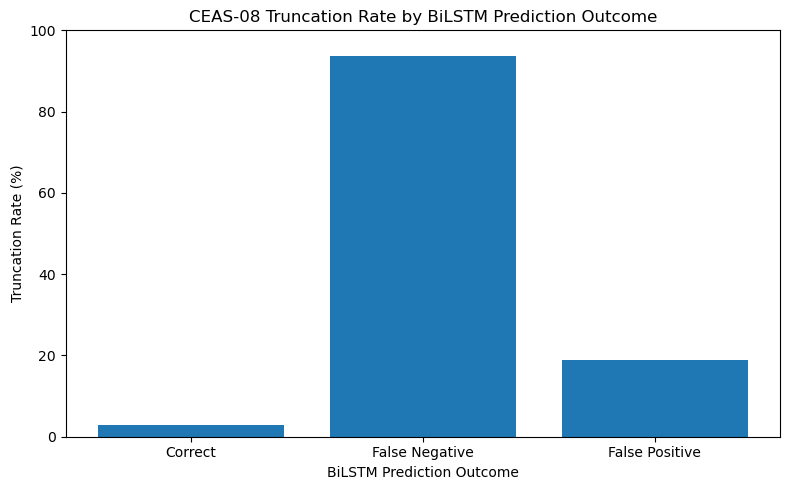

In [43]:
import matplotlib.pyplot as plt

plot_data = bilstm_characteristics.copy()

plt.figure(figsize=(8, 5))

plt.bar(
    plot_data["bilstm_result"],
    plot_data["Truncation_Rate"]
)

plt.ylabel("Truncation Rate (%)")
plt.xlabel("BiLSTM Prediction Outcome")
plt.title("CEAS-08 Truncation Rate by BiLSTM Prediction Outcome")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [44]:
from sklearn.metrics import confusion_matrix

# Relationship between truncation and BiLSTM false negatives

truncation_table = pd.crosstab(
    error_df["bilstm_truncated"],
    error_df["bilstm_fn"]
)

truncation_table.index = [
    "Not Truncated",
    "Truncated"
]

truncation_table.columns = [
    "Not False Negative",
    "False Negative"
]

print("Truncation vs BiLSTM False Negatives:")
display(truncation_table)

# Calculate proportions
print("\nFalse-negative rate by truncation status:")

for truncated_status, group in error_df.groupby("bilstm_truncated"):
    fn_rate = group["bilstm_fn"].mean() * 100
    label = "Truncated" if truncated_status else "Not Truncated"
    print(f"{label}: {fn_rate:.2f}%")

Truncation vs BiLSTM False Negatives:


,Not False Negative,False Negative
Not Truncated,32576,200
Truncated,3254,2934



False-negative rate by truncation status:
Not Truncated: 0.61%
Truncated: 47.41%


In [45]:
# Odds ratio for false negatives among truncated vs non-truncated emails

a = (
    error_df["bilstm_truncated"] &
    error_df["bilstm_fn"]
).sum()

b = (
    error_df["bilstm_truncated"] &
    ~error_df["bilstm_fn"]
).sum()

c = (
    ~error_df["bilstm_truncated"] &
    error_df["bilstm_fn"]
).sum()

d = (
    ~error_df["bilstm_truncated"] &
    ~error_df["bilstm_fn"]
).sum()

odds_ratio = (a * d) / (b * c)

print(f"Odds ratio: {odds_ratio:.2f}")

Odds ratio: 146.86


In [46]:
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(
    truncation_table
)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.10e}")

Chi-square statistic: 15410.42
Degrees of freedom: 1
p-value: 0.0000000000e+00


In [47]:
# Select representative BiLSTM-only false negatives
# These are errors made by BiLSTM but correctly classified by both classical models.

bilstm_only_fn_df = error_df[
    error_df["bilstm_only_fn"]
].copy()

print("BiLSTM-only false negatives:", len(bilstm_only_fn_df))

# Show a sample of representative cases
representative_fn = (
    bilstm_only_fn_df[
        [
            "email_id",
            "actual_label",
            "email_length",
            "bilstm_oov_rate",
            "bilstm_truncated",
            "lr_prediction",
            "svm_prediction"
        ]
    ]
    .sort_values("email_length", ascending=False)
    .head(10)
)

representative_fn

BiLSTM-only false negatives: 3116


,email_id,actual_label,email_length,bilstm_oov_rate,bilstm_truncated,lr_prediction,svm_prediction
33555,33555,1,964,0.058,True,1,1
29195,29195,1,955,0.096,True,1,1
30590,30590,1,778,0.086,True,1,1
22159,22159,1,640,0.060,True,1,1
24442,24442,1,640,0.060,True,1,1
24197,24197,1,639,0.060,True,1,1
24352,24352,1,639,0.060,True,1,1
24329,24329,1,639,0.060,True,1,1
31173,31173,1,639,0.060,True,1,1
24333,24333,1,639,0.060,True,1,1


In [48]:
# Final Error Analysis Summary

final_error_summary = pd.DataFrame({
    "Metric": [
        "CEAS-08 emails evaluated",
        "Logistic Regression errors",
        "Linear SVM errors",
        "BiLSTM errors",
        "BiLSTM false negatives",
        "BiLSTM-only false negatives",
        "BiLSTM FN rate - truncated",
        "BiLSTM FN rate - non-truncated",
        "Truncation odds ratio",
        "Chi-square statistic",
        "Chi-square p-value"
    ],
    "Value": [
        len(error_df),
        error_df["lr_error"].sum(),
        error_df["svm_error"].sum(),
        error_df["bilstm_error"].sum(),
        error_df["bilstm_fn"].sum(),
        error_df["bilstm_only_fn"].sum(),
        f"{error_df.loc[error_df['bilstm_truncated'], 'bilstm_fn'].mean()*100:.2f}%",
        f"{error_df.loc[~error_df['bilstm_truncated'], 'bilstm_fn'].mean()*100:.2f}%",
        f"{odds_ratio:.2f}",
        f"{chi2:.2f}",
        "< 0.001"
    ]
})

final_error_summary

,Metric,Value
0,CEAS-08 emails evaluated,38964
1,Logistic Regression errors,12958
2,Linear SVM errors,12167
3,BiLSTM errors,16934
4,BiLSTM false negatives,3134
5,BiLSTM-only false negatives,3116
6,BiLSTM FN rate - truncated,47.41%
7,BiLSTM FN rate - non-truncated,0.61%
8,Truncation odds ratio,146.86
9,Chi-square statistic,15410.42


In [50]:
import os

results_dir = "../results"

os.makedirs(results_dir, exist_ok=True)

error_df.to_csv(
    os.path.join(results_dir, "error_analysis_ceas08.csv"),
    index=False
)

final_error_summary.to_csv(
    os.path.join(results_dir, "error_analysis_summary.csv"),
    index=False
)

print("Error-analysis results saved successfully.")

Error-analysis results saved successfully.


In [51]:
print(os.path.abspath(results_dir))
print(os.listdir(results_dir))

C:\Users\Yug Jain\Downloads\results
['error_analysis_ceas08.csv', 'error_analysis_summary.csv']
